<a href="https://colab.research.google.com/github/calettikarla-2822/Metodos-numericos-1/blob/main/Diferencias_Divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Función del algoritmo de Newton
def diferencias_divididas_newton(x, y):
    """
    Calcula los coeficientes del polinomio de interpolación de Newton
    usando el algoritmo de diferencias divididas.
    """
    n = len(x)
    # Matriz de n x n llena de ceros para la tabla F
    F = np.zeros((n, n))

    # La primera columna (F_i,0) son los valores de y (f(x_i))
    for i in range(n):
        F[i, 0] = y[i]

    for i in range(1, n):
        for j in range(1, i + 1):
            # Fórmula: F_{i,j} = (F_{i,j-1} - F_{i-1,j-1}) / (x_i - x_{i-j})
            F[i, j] = (F[i, j-1] - F[i-1, j-1]) / (x[i] - x[i-j])

    # Los coeficientes del polinomio son la diagonal de la matriz F
    coeficientes = [F[i, i] for i in range(n)]
    return coeficientes

print("Función 'diferencias_divididas_newton' definida.")

Función 'diferencias_divididas_newton' definida.


In [3]:
# Función para construir, imprimir y graficar el polinomio
def construir_y_graficar_polinomio(x_datos, y_datos, coef):
    """
    Toma los coeficientes y los datos, construye el polinomio con sympy,
    lo imprime en pantalla y genera una gráfica.
    """
    # Definimos la variable simbólica x
    x_sym = sp.Symbol('x')

    # Construimos el polinomio de Newton
    polinomio = coef[0]
    termino = 1
    for i in range(1, len(coef)):
        termino *= (x_sym - x_datos[i-1])
        polinomio += coef[i] * termino

    print("="*50)
    print("POLINOMIO DE NEWTON CONSTRUIDO:")
    print("="*50)
    sp.pprint(polinomio)

    # Evaluamos el polinomio en el punto x=1.5 para verificar
    valor_evaluado = polinomio.subs(x_sym, 1.5).evalf()
    print(f"\nEvaluación en x = 1.5: P(1.5) = {valor_evaluado}")

    # --- GRÁFICA ---
    # Convertimos el polinomio simbólico a una función numérica para graficar
    f_num = sp.lambdify(x_sym, polinomio, 'numpy')

    # Creamos un rango de valores para x
    x_graf = np.linspace(min(x_datos) - 0.2, max(x_datos) + 0.2, 100)
    y_graf = f_num(x_graf)

    plt.figure(figsize=(8, 5))
    plt.plot(x_graf, y_graf, label='Polinomio de Newton \(P_4(x)\)', color='blue')
    plt.scatter(x_datos, y_datos, color='red', zorder=5, label='Datos originales')

    # Resaltamos el punto x=1.5
    plt.scatter([1.5], [valor_evaluado], color='green', marker='*', s=150, zorder=6,
                label=f'P(1.5) = {valor_evaluado:.7f}')

    plt.title('Interpolación de Newton - Ejemplo 1')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

print("Función 'construir_y_graficar_polinomio' definida.")

Función 'construir_y_graficar_polinomio' definida.


<>:35: SyntaxWarning: invalid escape sequence '\('
<>:35: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_2613/2826016607.py:35: SyntaxWarning: invalid escape sequence '\('
  plt.plot(x_graf, y_graf, label='Polinomio de Newton \(P_4(x)\)', color='blue')


Coeficientes de la diagonal (F_0,0, F_1,1, ... F_n,n):
F_0,0 = 0.7651977
F_1,1 = -0.4837057
F_2,2 = -0.1087339
F_3,3 = 0.0658784
F_4,4 = 0.0018251
POLINOMIO DE NEWTON CONSTRUIDO:
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Evaluación en x = 1.5: P(1.5) = 0.511819994238683


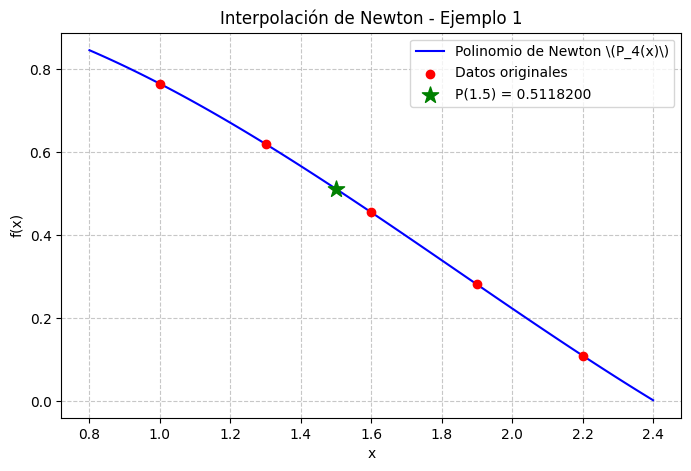

In [4]:
# Ejemplo 1
# Datos de la tabla 3.11
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

# 1. Obtener los coeficientes
coeficientes = diferencias_divididas_newton(x_datos, y_datos)

print("Coeficientes de la diagonal (F_0,0, F_1,1, ... F_n,n):")
for i, c in enumerate(coeficientes):
    print(f"F_{i},{i} = {c:.7f}")

# 2. Construir y graficar el polinomio
construir_y_graficar_polinomio(x_datos, y_datos, coeficientes)